# P1 · Dữ liệu & điều phối — Bước 1 & 4

**Input (cell đầu tự nạp):** data/raw/*.csv (M5 thô)

**Output (cell cuối tự lưu):** common/{sample_ids,segment_labels,rolling_windows} + data/processed/data_long.parquet

**Code mẫu tham khảo:** `notebooks/M5_reference.ipynb` phần **§1**.

> Chạy được **cell đầu** (thấy `✅ Input sẵn sàng`) = đủ input để làm phần của bạn. Code ở khu vực giữa. Cuối cùng chạy **cell lưu output**.

In [1]:
from pathlib import Path
def _need(p, hint):
    assert Path(p).exists(), f"❌ THIẾU INPUT: {p}\n   → {hint}"

import numpy as np, pandas as pd, yaml
_need("common/config.yaml", "clone repo để có common/")
_need("data/raw/sales_train_evaluation.csv", "đặt dữ liệu M5 vào data/raw/")
_need("data/raw/calendar.csv", "đặt calendar.csv vào data/raw/ (có sẵn trong repo)")
_need("data/raw/sell_prices.csv", "đặt sell_prices.csv vào data/raw/")
CFG = yaml.safe_load(open("common/config.yaml", encoding="utf-8"))
SEED = CFG["seed"]; H = CFG["horizon"]; Q = CFG["quantiles"]
SP = CFG["split"]; RL = CFG["rolling"]; SBC = CFG["sbc"]; SAMP = CFG["sampling"]
ID_COLS = ["id","item_id","dept_id","cat_id","store_id","state_id"]
calendar = pd.read_csv("data/raw/calendar.csv")
prices   = pd.read_csv("data/raw/sell_prices.csv")
sales    = pd.read_csv("data/raw/sales_train_evaluation.csv")   # d_1..d_1941
D_COLS = [c for c in sales.columns if c.startswith("d_")]
train_days = [f"d_{i}" for i in range(1, SP["train_end"]+1)]
print("✅ Input sẵn sàng — sales", sales.shape, "| calendar", calendar.shape, "| prices", prices.shape)

✅ Input sẵn sàng — sales (30490, 1947) | calendar (1969, 14) | prices (6841121, 4)


## Phần code chính (bước 1 & 4) — đã hoàn thành

In [2]:
# ADI & CV^2 trên train (vectorised)
mat = sales[train_days].to_numpy(dtype=np.float32); T = mat.shape[1]
nz = mat > 0; n_nz = nz.sum(1)
mean_nz = np.divide(np.where(nz,mat,0).sum(1), n_nz, out=np.zeros(len(mat)), where=n_nz>0)
sq = np.where(nz,mat**2,0).sum(1)
var_nz = np.clip(np.divide(sq,n_nz,out=np.zeros(len(mat)),where=n_nz>0)-mean_nz**2, 0, None)
with np.errstate(divide="ignore", invalid="ignore"):
    ADI = np.where(n_nz>0, T/n_nz, np.inf)
    CV2 = np.where(mean_nz>0, (np.sqrt(var_nz)/mean_nz)**2, 0.0)
seg = sales[ID_COLS].copy(); seg["series_id"] = seg["id"]
seg["zero_rate"] = 1 - n_nz/T; seg["ADI"] = ADI; seg["CV2"] = CV2

In [3]:
# Nhãn SBC (4 nhóm)
cond = [(seg.ADI<SBC["adi_threshold"])&(seg.CV2<SBC["cv2_threshold"]),
        (seg.ADI<SBC["adi_threshold"])&(seg.CV2>=SBC["cv2_threshold"]),
        (seg.ADI>=SBC["adi_threshold"])&(seg.CV2<SBC["cv2_threshold"]),
        (seg.ADI>=SBC["adi_threshold"])&(seg.CV2>=SBC["cv2_threshold"])]
seg["segment"] = np.select(cond, ["smooth","erratic","intermittent","lumpy"], default="intermittent")
print(seg.segment.value_counts().to_dict())

{'intermittent': 23095, 'lumpy': 5921, 'smooth': 980, 'erratic': 494}


In [4]:
# Mẫu phân tầng: toàn bộ smooth+erratic, cap intermittent+lumpy
rare = {"smooth","erratic"}; cap = SAMP["cap"]; picks = []
for s, g in seg.groupby("segment"):
    n = len(g) if s in rare else min(len(g), cap)
    picks.append(g.sample(n=n, random_state=SEED))
sample_ids = sorted(pd.concat(picks)["series_id"].tolist()); print("Mẫu:", len(sample_ids))

Mẫu: 3474


In [5]:
# Bước 1: wide -> long (chuỗi mẫu) + join calendar/giá + feature
CAL = ["d","date","wm_yr_wk","wday","month","year","event_name_1","event_type_1","snap_CA","snap_TX","snap_WI"]
sub = sales[sales.id.isin(sample_ids)]
long = sub.melt(id_vars=ID_COLS, value_vars=D_COLS, var_name="d", value_name="sales")
long = long.merge(calendar[CAL], on="d", how="left").merge(prices, on=["store_id","item_id","wm_yr_wk"], how="left")
long["series_id"]=long["id"]; long["date"]=pd.to_datetime(long["date"]); long["d_int"]=long["d"].str.slice(2).astype("int32")
long["is_event"]=long["event_name_1"].notna().astype("int8")
long["snap"]=0
for st,c in {"CA":"snap_CA","TX":"snap_TX","WI":"snap_WI"}.items():
    m=long.state_id==st; long.loc[m,"snap"]=long.loc[m,c].values
long["snap"]=long["snap"].astype("int8"); long["sales"]=long["sales"].astype("float32")
long=long.merge(seg[["series_id","segment"]],on="series_id",how="left").sort_values(["series_id","d_int"]).reset_index(drop=True)
print("data_long:", long.shape)

data_long: (6743034, 24)


In [6]:
# Bước 4: cửa sổ rolling-origin (>=3), tất cả <= d_1941
val_len = SP["val_end"]-SP["train_end"]; rows=[]
for k in range(RL["n_windows"]):
    te=SP["test_end"]-k*RL["step"]; ts=te-H+1; ve=ts-1; tr=ve-val_len
    assert tr>=1 and te<=SP["max_actual_day"] and te-ts+1==H
    rows.append(dict(window=f"W{k+1}",train_end=tr,val_end=ve,test_start=ts,test_end=te))
windows = pd.DataFrame(rows); print(windows.to_string(index=False))

window  train_end  val_end  test_start  test_end
    W1       1885     1913        1914      1941
    W2       1857     1885        1886      1913
    W3       1829     1857        1858      1885


In [ ]:
# ===== CELL CUỐI: lưu OUTPUT (đừng sửa format) =====
Path("common").mkdir(exist_ok=True); Path("data/processed").mkdir(parents=True, exist_ok=True)
seg[["series_id","ADI","CV2","zero_rate","segment"]].to_parquet("common/segment_labels.parquet", index=False)
pd.DataFrame({"series_id": sample_ids}).to_csv("common/sample_ids.csv", index=False)
windows.to_csv("common/rolling_windows.csv", index=False)
long.to_parquet("data/processed/data_long.parquet", index=False)
print("✅ Đã lưu common/{segment_labels,sample_ids,rolling_windows} + data/processed/data_long.parquet")

## Biểu đồ & diễn giải (bước 1 & 4)

*Đọc từ `common/*` đã lưu — minh họa, **không tính lại / không ghi output**.*

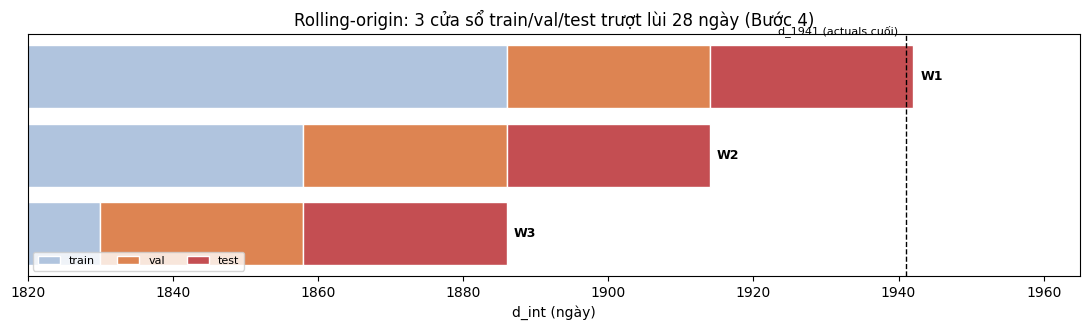

In [7]:
# Biểu đồ 1 — Rolling-origin: 3 cửa sổ train/val/test trượt lùi (Bước 4)
import matplotlib.pyplot as plt
import pandas as pd
w = pd.read_csv("common/rolling_windows.csv")
fig, ax = plt.subplots(figsize=(11, 3.4))
for i, r in w.iterrows():
    y = len(w) - i
    ax.barh(y, int(r.train_end), left=1, color="#B0C4DE", edgecolor="white", label="train" if i == 0 else "")
    ax.barh(y, int(r.val_end) - int(r.train_end), left=int(r.train_end) + 1, color="#DD8452", edgecolor="white", label="val" if i == 0 else "")
    ax.barh(y, int(r.test_end) - int(r.test_start) + 1, left=int(r.test_start), color="#C44E52", edgecolor="white", label="test" if i == 0 else "")
    ax.text(int(r.test_end) + 2, y, str(r.window), va="center", fontsize=9, fontweight="bold")
ax.axvline(1941, ls="--", color="black", lw=1)
ax.text(1940, len(w) + 0.55, "d_1941 (actuals cuối)", ha="right", fontsize=8)
ax.set_yticks([]); ax.set_xlim(1820, 1965)
ax.set_xlabel("d_int (ngày)")
ax.set_title("Rolling-origin: 3 cửa sổ train/val/test trượt lùi 28 ngày (Bước 4)")
ax.legend(loc="lower left", ncol=3, fontsize=8)
fig.tight_layout(); plt.show()

**Hình 1 — Rolling-origin.** Ba cửa sổ trượt lùi 28 ngày (W1→W3): train nở dần về quá khứ, **test luôn ≤ d_1941** (phạm vi có actuals). Thiết kế cho đánh giá rolling-origin ổn định, không rò rỉ tương lai (test không bao giờ nằm trong train).

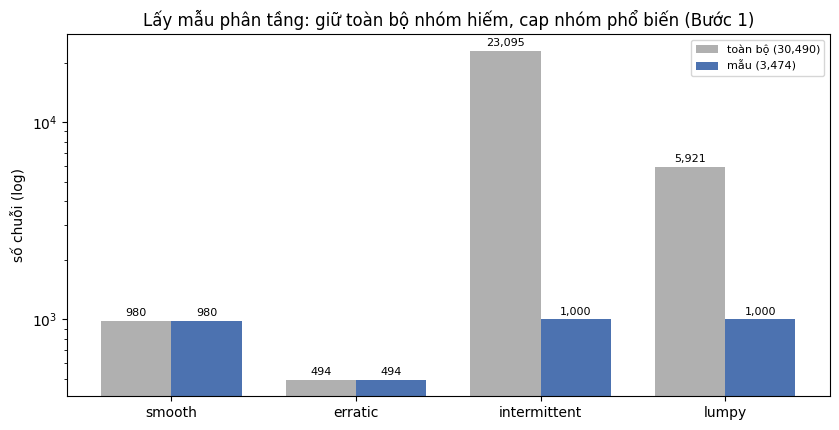

In [8]:
# Biểu đồ 2 — Lấy mẫu phân tầng: full 30.490 vs mẫu 3.474 theo nhóm (Bước 1)
import matplotlib.pyplot as plt
import pandas as pd, numpy as np
seg = pd.read_parquet("common/segment_labels.parquet")
samp_ids = set(pd.read_csv("common/sample_ids.csv")["series_id"])
order = ["smooth", "erratic", "intermittent", "lumpy"]
full = seg["segment"].value_counts().reindex(order)
samp = seg[seg["series_id"].isin(samp_ids)]["segment"].value_counts().reindex(order)
x = np.arange(len(order)); bw = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.4))
b1 = ax.bar(x - bw/2, full.values, bw, label=f"toàn bộ ({int(full.sum()):,})", color="#B0B0B0")
b2 = ax.bar(x + bw/2, samp.values, bw, label=f"mẫu ({int(samp.sum()):,})", color="#4C72B0")
ax.set_yscale("log")
for b, v in list(zip(b1, full.values)) + list(zip(b2, samp.values)):
    ax.text(b.get_x() + b.get_width()/2, v * 1.06, f"{int(v):,}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel("số chuỗi (log)")
ax.set_title("Lấy mẫu phân tầng: giữ toàn bộ nhóm hiếm, cap nhóm phổ biến (Bước 1)")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

**Hình 2 — Lấy mẫu phân tầng.** Quy tắc *giữ hiếm, cap phổ biến*: lấy **100%** smooth (980) + erratic (494), giới hạn intermittent/lumpy ở **1.000** → **3.474** chuỗi. Nhờ vậy hai nhóm hiếm (chỉ ~5% tổng thể) không bị nhóm phổ biến lấn át khi phân tích theo đặc tính.

C:\Users\Admin\AppData\Local\Temp\ipykernel_43476\1270989347.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=order, patch_artist=True, showfliers=False, medianprops=dict(color="black"))


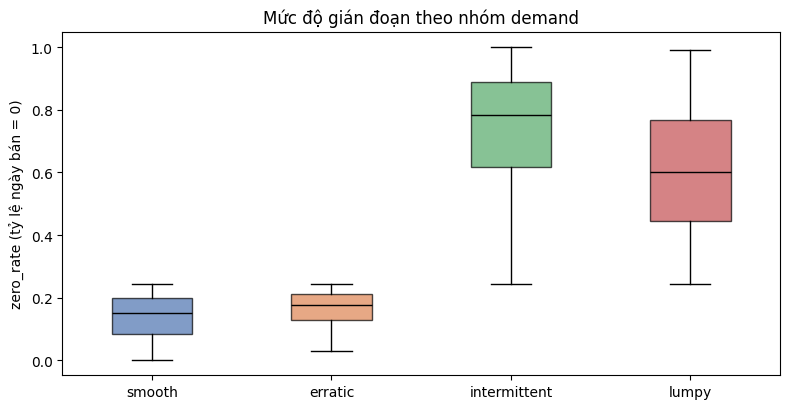

In [9]:
# Biểu đồ 3 — Mức độ gián đoạn (zero_rate) theo nhóm (toàn bộ 30.490 chuỗi)
import matplotlib.pyplot as plt
import pandas as pd
seg = pd.read_parquet("common/segment_labels.parquet")
order = ["smooth", "erratic", "intermittent", "lumpy"]
data = [seg.loc[seg["segment"] == s, "zero_rate"].values for s in order]
cols = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
fig, ax = plt.subplots(figsize=(8, 4.2))
bp = ax.boxplot(data, labels=order, patch_artist=True, showfliers=False, medianprops=dict(color="black"))
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c); patch.set_alpha(0.7)
ax.set_ylabel("zero_rate (tỷ lệ ngày bán = 0)")
ax.set_title("Mức độ gián đoạn theo nhóm demand")
fig.tight_layout(); plt.show()

**Hình 3 — Mức độ gián đoạn.** `zero_rate` tăng dần smooth → intermittent: nhóm *thưa* có **~60–90%** ngày bằng 0. Đây là căn cứ để toàn dự án ưu tiên **dự báo xác suất** và **tách nhóm** khi đánh giá (metric điểm kém ý nghĩa với chuỗi nhiều 0).

### Tóm tắt khâu dữ liệu
Đầu ra P1 gồm: **nhãn SBC cho 30.490 chuỗi** (95% gián đoạn), **mẫu phân tầng 3.474** cân bằng, và **3 cửa sổ rolling-origin ≤ d_1941**. Đây là input chuẩn hoá, tất định (seed 42) cho P2–P5.